# Simulated examples

This tutorial reproduces the two simulated examples of the paper. In both, the source and target cells are unpaired
samples of two classes, and optimal transport with the squared Euclidean cost sends cells to the wrong class. CloneOT
learns the cost from a few clones and maps every new cell to its own class.

* **T-shape** (Howard et al., 2024): a vertical bar on the left moves to the right and a horizontal bar on top moves
  down. Moving the left bar down and the top bar to the right is cheaper. The cells form clones of two sister cells,
  and 20% of the clones are labeled.
* **Rotated moons** (OT-SI): the target is the two moons rotated by 90 degrees, and the only lineage is which source
  moon corresponds to which rotated moon.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cloneot as cot
from cloneot.datasets import class_accuracy, label_fraction, rotated_moons, t_shape

## T-shape

We draw 400 training cells, 400 new source cells for testing, and a large reference sample of target cells that
tells which class a prediction lands on.

In [2]:
data, test, reference = t_shape(400, seed=0), t_shape(400, seed=100), t_shape(4000, seed=200)
labels = label_fraction(data['source_clone'], data['target_clone'], fraction=0.2, seed=0)
print(f"{len(data['source'])} source and {len(data['target'])} target cells, "
      f"{len(set(labels[0]) - {-1})} labeled clones")

400 source and 400 target cells, 40 labeled clones


Without clone labels, CloneOT is entropic optimal transport with the squared Euclidean cost, the solver underlying
CellOT. With the labels, it learns the cost.

In [3]:
euclidean = cot.CloneOT().fit(data['source'], data['target']).fit_map()
cloneot = cot.CloneOT().fit(data['source'], data['target'], *labels).fit_map()

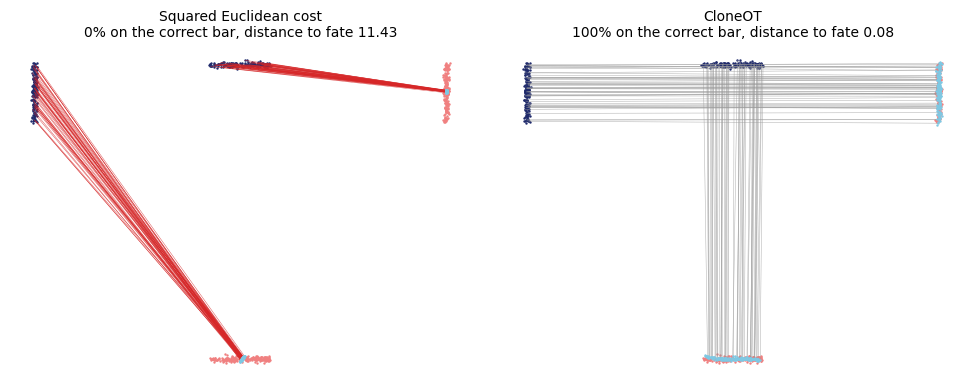

In [4]:
def summarize(model, test, reference):
    prediction = model.transport(test['source'])
    nearest = ((prediction[:, None] - reference['target'][None]) ** 2).sum(-1).argmin(1)
    correct = reference['target_class'][nearest] == test['source_class']
    error = np.linalg.norm(prediction - test['fate'](test['source']), axis=1).mean()
    return prediction, correct, error

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, (name, model) in zip(axes, [('Squared Euclidean cost', euclidean), ('CloneOT', cloneot)]):
    prediction, correct, error = summarize(model, test, reference)
    cot.pl.transport(test['source'], test['target'], prediction, correct, ax=ax, legend=False,
                     title=f'{name}\n{correct.mean():.0%} on the correct bar, distance to fate {error:.2f}')
    ax.title.set_fontsize(10)
plt.tight_layout()

Red rays end on the wrong bar. The squared Euclidean cost sends the left bar down and the top bar to the right,
whereas CloneOT places every new cell on its own bar and recovers the translation of each bar.

## Rotated moons

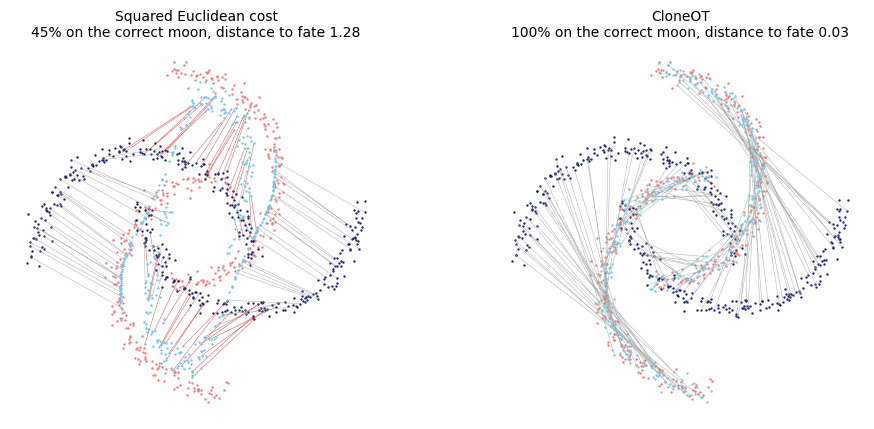

In [5]:
data, test, reference = rotated_moons(400, seed=0), rotated_moons(400, seed=100), rotated_moons(4000, seed=200)
labels = (data['source_clone'], data['target_clone'])        # the two moons are the two clones
euclidean = cot.CloneOT().fit(data['source'], data['target']).fit_map()
cloneot = cot.CloneOT().fit(data['source'], data['target'], *labels).fit_map()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, (name, model) in zip(axes, [('Squared Euclidean cost', euclidean), ('CloneOT', cloneot)]):
    prediction, correct, error = summarize(model, test, reference)
    cot.pl.transport(test['source'], test['target'], prediction, correct, ax=ax, legend=False,
                     title=f'{name}\n{correct.mean():.0%} on the correct moon, distance to fate {error:.2f}')
    ax.title.set_fontsize(10)
plt.tight_layout()

The only supervision is which moon corresponds to which rotated moon, two clones without any pairs of cells.
CloneOT learns a cost under which the cheapest transport is the rotation itself.